# Lab 5-08：Claude Agent SDK——把 Claude Code 這個 harness 當函式庫用

**目標**：認識 Claude Agent SDK（`claude-agent-sdk`）。它跟前面幾個框架不一樣：不是讓你組一個迴圈，
而是直接把 Claude Code 這個**現成的 harness**（檔案與 shell 工具、權限、hooks、MCP、子 agent、skills）交給你的程式驅動。

**你會學到**
- `query()` 與 `ClaudeAgentOptions`：harness 的每一塊對應到哪個參數
- 自訂工具＝程式內的 MCP server（`@tool`＋`create_sdk_mcp_server`）
- 兩道權限關卡：`can_use_tool` 回呼與 `PreToolUse` hook
- 子 agent（`agents=`）、skills、CLAUDE.md 記憶怎麼設定

**前置**：Lab 5-C（06）。實際呼叫需要 `ANTHROPIC_API_KEY` 與 Claude Code CLI；**沒有金鑰也能跑完這本**：
工具、權限、hook 都是普通的 Python 函式，可以先在本機測，只有最後的 `query()` 會跳過。

**對應投影片**：「Harness 是什麼」「選型：Agent 框架（二）」「流程圖外殼＋harness 核心」

![Claude Agent SDK 三層架構圖](images/claude_sdk.jpg)

*圖：上層是你的程式（query、自訂 MCP 工具、權限回呼、hooks）；中層是 Claude Code CLI，迴圈和內建工具都在這裡；下層是 Claude 模型。CLI 每次要用工具前，會回頭問你的 can_use_tool。*

## Step 1：檢查環境

需要兩樣東西：Claude Code CLI（`claude` 指令，SDK 會啟動它當子行程）和 `ANTHROPIC_API_KEY`。

In [1]:
import os
import shutil

import claude_agent_sdk

HAS_KEY = bool(os.getenv("ANTHROPIC_API_KEY"))
print("claude-agent-sdk 版本：", claude_agent_sdk.__version__)
print("Claude Code CLI：", "有" if shutil.which("claude") else "沒有")
if not HAS_KEY:
    print("需要金鑰，以下為預期行為說明：沒有 ANTHROPIC_API_KEY，實際呼叫模型的 cell 會跳過，其餘照常執行。")

claude-agent-sdk 版本： 0.2.185
Claude Code CLI： 有
需要金鑰，以下為預期行為說明：沒有 ANTHROPIC_API_KEY，實際呼叫模型的 cell 會跳過，其餘照常執行。


## Step 2：自訂工具＝程式內的 MCP server

Claude Code 外接工具一律走 MCP（模組 7 會自己寫 MCP server）。SDK 提供捷徑：用 `@tool` 定義、`create_sdk_mcp_server` 包起來，
工具就在你的 Python 行程裡執行，不用另外開伺服器。

回傳格式是 MCP 的 `{"content": [{"type": "text", "text": ...}]}`。工具在 Claude 那邊的全名是 `mcp__<server>__<tool>`。

In [2]:
from claude_agent_sdk import create_sdk_mcp_server, tool

import oncall_tools as ot

ot.reset_env()


def text(s: str) -> dict:
    return {"content": [{"type": "text", "text": s}]}


@tool("read_logs", "讀應用程式日誌，可依服務與等級過濾", ot.ReadLogsArgs.model_json_schema())
async def read_logs_tool(args: dict) -> dict:
    return text(ot.read_logs(args.get("service"), args.get("level"), args.get("keyword"), args.get("limit", 8)))


@tool("query_metrics", "查某個服務的監控指標", ot.QueryMetricsArgs.model_json_schema())
async def query_metrics_tool(args: dict) -> dict:
    return text(ot.query_metrics(args["service"], args.get("metric", "error_rate")))


@tool("restart_service", "重啟一個服務（寫入動作）", ot.RestartArgs.model_json_schema())
async def restart_tool(args: dict) -> dict:
    return text(ot.restart_service(args["service"]))


oncall_server = create_sdk_mcp_server("oncall", tools=[read_logs_tool, query_metrics_tool, restart_tool])
print("MCP server：", oncall_server["name"], oncall_server["type"])

MCP server： oncall sdk


工具就是普通的 async 函式，沒有模型也能直接測：

In [3]:
print((await query_metrics_tool.handler({"service": "order-db-proxy", "metric": "pool_used"}))["content"][0]["text"])

order-db-proxy pool_used 最近：14:00=46, 14:05=50, 14:10=50, 14:15=50, 14:20=50, 14:25=50；目前 50（上限 50）


## Step 3：第一道關卡——`can_use_tool`

每次 Claude 想用一個工具（內建的或 MCP 的），CLI 都會先問你的回呼：允許、拒絕（附理由給模型看），或改參數再允許。
這是 harness 版的「權限」，跟 05 的審批同一個位置。規則：
- 讀的工具一律放行
- `Bash` 只准 `ls`、`cat`、`grep` 開頭的指令
- 重啟只准白名單服務，而且要「人」點頭（這裡用 `HUMAN_APPROVES` 模擬）

In [4]:
from claude_agent_sdk import PermissionResultAllow, PermissionResultDeny, ToolPermissionContext

READ_ONLY = {"Read", "Grep", "Glob", "mcp__oncall__read_logs", "mcp__oncall__query_metrics"}
ALLOWED_RESTART = {"order-db-proxy", "notification"}
HUMAN_APPROVES = {"order-db-proxy"}  # 模擬：主管只核准這個


async def can_use_tool(tool_name: str, tool_input: dict, context: ToolPermissionContext):
    if tool_name in READ_ONLY:
        return PermissionResultAllow()
    if tool_name == "Bash":
        cmd = tool_input.get("command", "")
        if cmd.split()[0] in {"ls", "cat", "grep"}:
            return PermissionResultAllow()
        return PermissionResultDeny(message=f"值班 agent 不准執行：{cmd}")
    if tool_name == "mcp__oncall__restart_service":
        service = tool_input.get("service")
        if service not in ALLOWED_RESTART:
            return PermissionResultDeny(message=f"規範禁止重啟 {service}")
        if service in HUMAN_APPROVES:
            return PermissionResultAllow()
        return PermissionResultDeny(message=f"值班主管拒絕重啟 {service}")
    return PermissionResultDeny(message=f"{tool_name} 不在允許清單")

## Step 4：第二道關卡——`PreToolUse` hook

hook 是在固定時間點插進來的函式（工具前、工具後、使用者送出訊息時、子 agent 結束時…）。
跟 `can_use_tool` 的差別：hook 可以只針對某些工具（`matcher`），也適合做**稽核紀錄**這種「每次都要做、不是判斷」的事。
這裡做兩件事：所有寫入動作記一筆稽核，`rm -rf` 不管誰允許都擋。

In [5]:
from claude_agent_sdk import HookMatcher

AUDIT = []


async def audit_and_block(input_data: dict, tool_use_id: str | None, context) -> dict:
    name, args = input_data["tool_name"], input_data["tool_input"]
    if name.startswith("mcp__oncall__restart") or name == "Bash":
        AUDIT.append((name, args))
    if name == "Bash" and "rm -rf" in args.get("command", ""):
        return {"hookSpecificOutput": {"hookEventName": "PreToolUse", "permissionDecision": "deny",
                                       "permissionDecisionReason": "hook：禁止 rm -rf"}}
    return {}


HOOKS = {"PreToolUse": [HookMatcher(matcher="Bash|mcp__oncall__restart_service", hooks=[audit_and_block])]}

## Step 5：不用模型，先把關卡測一遍

假裝 Claude 依序提出了 7 個工具請求，讓它們通過 hook 和 `can_use_tool`。這就是權限設計的單元測試——上線前一定要做。

In [6]:
REQUESTS = [
    ("mcp__oncall__query_metrics", {"service": "order-db-proxy", "metric": "pool_used"}),
    ("Read", {"file_path": "AGENTS.md"}),
    ("Bash", {"command": "grep ERROR data/app.log"}),
    ("Bash", {"command": "rm -rf /var/lib/orders"}),
    ("mcp__oncall__restart_service", {"service": "payment-api"}),
    ("mcp__oncall__restart_service", {"service": "notification"}),
    ("mcp__oncall__restart_service", {"service": "order-db-proxy"}),
]

decisions = []
for name, args in REQUESTS:
    hook_out = await audit_and_block({"tool_name": name, "tool_input": args}, None, None)
    if hook_out:
        decisions.append((name, args, "hook 擋下", hook_out["hookSpecificOutput"]["permissionDecisionReason"]))
        continue
    perm = await can_use_tool(name, args, ToolPermissionContext())
    decisions.append((name, args, "允許" if perm.behavior == "allow" else "拒絕", getattr(perm, "message", "")))

for name, args, verdict, why in decisions:
    print(f"{verdict:<5} {name:<32} {str(args)[:40]:<42} {why}")
print("\n稽核紀錄：", len(AUDIT), "筆")

允許    mcp__oncall__query_metrics       {'service': 'order-db-proxy', 'metric':    
允許    Read                             {'file_path': 'AGENTS.md'}                 
允許    Bash                             {'command': 'grep ERROR data/app.log'}     
hook 擋下 Bash                             {'command': 'rm -rf /var/lib/orders'}      hook：禁止 rm -rf
拒絕    mcp__oncall__restart_service     {'service': 'payment-api'}                 規範禁止重啟 payment-api
拒絕    mcp__oncall__restart_service     {'service': 'notification'}                值班主管拒絕重啟 notification
允許    mcp__oncall__restart_service     {'service': 'order-db-proxy'}              

稽核紀錄： 5 筆


畫成一張表：每一列是一個請求，顏色是結果。注意 `rm -rf` 是在 hook 那一關就被擋，根本輪不到 `can_use_tool`。

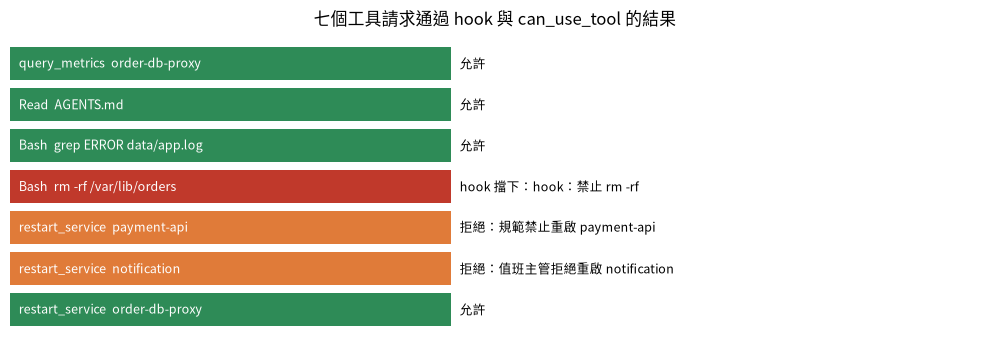

In [7]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

color = {"允許": "#2e8b57", "拒絕": "#e07b39", "hook 擋下": "#c0392b"}
fig, ax = plt.subplots(figsize=(10, 3.6))
for i, (name, args, verdict, why) in enumerate(decisions):
    ax.barh(i, 1, color=color[verdict])
    label = f"{name.replace('mcp__oncall__', '')}  {list(args.values())[0]}"
    ax.text(0.02, i, label, va="center", color="white", fontsize=9)
    ax.text(1.02, i, f"{verdict}：{why}" if why else verdict, va="center", fontsize=9)
ax.set_xlim(0, 2.2)
ax.set_yticks([])
ax.invert_yaxis()
ax.axis("off")
ax.set_title("七個工具請求通過 hook 與 can_use_tool 的結果")
plt.tight_layout()
plt.show()

## Step 6：子 agent、skills、記憶

- **子 agent**：`agents={"名稱": AgentDefinition(...)}`，Claude 用內建的 Agent／Task 工具呼叫，子 agent 有自己的 context 與工具清單。
- **skills**：放在工作目錄的 `.claude/skills/<名稱>/SKILL.md`，`skills=["ops-runbook"]` 開啟（SDK 會自動設定 `setting_sources`）。
- **記憶**：Claude Code 啟動時讀工作目錄的 `CLAUDE.md`；可以在裡面寫 `@AGENTS.md` 把 06 的值班慣例匯入。

把 06 的 `oncall/` 整理成 Claude Code 認得的目錄結構：

In [8]:
from pathlib import Path

WS = Path("workspace_claude")
shutil.rmtree(WS, ignore_errors=True)
shutil.copytree("oncall/skills", WS / ".claude" / "skills")
shutil.copy("oncall/AGENTS.md", WS / "AGENTS.md")
(WS / "CLAUDE.md").write_text("# 晨光外送值班\n\n@AGENTS.md\n", encoding="utf-8")
for p in sorted(WS.rglob("*")):
    if p.is_file():
        print(p)

workspace_claude/.claude/skills/incident-report/SKILL.md
workspace_claude/.claude/skills/ops-runbook/SKILL.md
workspace_claude/AGENTS.md
workspace_claude/CLAUDE.md


## Step 7：組裝 options

對照 06 的 `create_deep_agent`，幾乎一一對應。注意 `tools=[]`：不給內建的 Bash／Edit，只留讀檔＋我們的 MCP 工具，權限面最小。

In [9]:
from claude_agent_sdk import AgentDefinition, ClaudeAgentOptions

options = ClaudeAgentOptions(
    system_prompt="你是晨光外送的值班 agent。用繁體中文回答，先講結論再列證據。",
    cwd=str(WS),
    tools=["Read", "Grep", "Glob"],                       # 內建工具只留讀的
    mcp_servers={"oncall": oncall_server},                # 自訂工具
    allowed_tools=["mcp__oncall__read_logs", "mcp__oncall__query_metrics"],  # 這兩個免問
    agents={"log-checker": AgentDefinition(
        description="查證一個懷疑的原因：讀日誌、查指標，回報證據",
        prompt="你是唯讀的查證員。用工具查完後，回三行：結論、證據、信心。",
        tools=["mcp__oncall__read_logs", "mcp__oncall__query_metrics"],
    )},
    skills=["ops-runbook"],
    can_use_tool=can_use_tool,
    hooks=HOOKS,
    max_turns=10,
)
print({k: v for k, v in vars(options).items() if k in ("cwd", "tools", "allowed_tools", "skills", "max_turns")})

{'tools': ['Read', 'Grep', 'Glob'], 'allowed_tools': ['mcp__oncall__read_logs', 'mcp__oncall__query_metrics'], 'max_turns': 10, 'cwd': 'workspace_claude', 'skills': ['ops-runbook']}


| 06 deepagents | Claude Agent SDK |
|---|---|
| `tools=[...]` | `mcp_servers=`（自訂）＋`tools=`（內建） |
| `subagents=[...]` | `agents={...: AgentDefinition}` |
| `skills=["/skills/"]` | `.claude/skills/`＋`skills=[...]` |
| `memory=["/AGENTS.md"]` | `CLAUDE.md`（可 `@` 匯入其他檔案） |
| `interrupt_on=` | `can_use_tool`、`hooks`、`permission_mode` |
| `checkpointer` | CLI 自己存 session，用 `resume=session_id` 接續 |
| `recursion_limit` | `max_turns`、`max_budget_usd` |

## Step 8：實際執行（需要金鑰）

有金鑰時，`query()` 會啟動 CLI、跑完整個迴圈，一路吐出訊息：`AssistantMessage`（文字與工具呼叫）、`UserMessage`（工具結果）、
最後一則 `ResultMessage`（花費、輪數、session id）。

In [10]:
from claude_agent_sdk import AssistantMessage, ResultMessage, TextBlock, ToolUseBlock, query

PROMPT = "下單一直 502。先依 ops-runbook 查證，必要時派 log-checker 子 agent；確認是連線池用盡就重啟 order-db-proxy，最後三行回報。"


async def run_oncall() -> None:
    async for msg in query(prompt=PROMPT, options=options):
        if isinstance(msg, AssistantMessage):
            for block in msg.content:
                if isinstance(block, TextBlock):
                    print("Claude：", block.text[:200])
                elif isinstance(block, ToolUseBlock):
                    print("→ 工具：", block.name, block.input)
        elif isinstance(msg, ResultMessage):
            print(f"結束：{msg.num_turns} 輪，花費 {msg.total_cost_usd} 美元，session {msg.session_id}")


if HAS_KEY:
    await run_oncall()
    print("重啟過的服務：", ot.restarted())
else:
    print("需要金鑰，以下為預期行為說明（跳過實際呼叫）：")
    print("""  1. Claude 讀 .claude/skills/ops-runbook/SKILL.md（skill 被觸發）
  2. → mcp__oncall__read_logs {"level": "ERROR"}            （allowed_tools，免問）
  3. → Agent/Task 呼叫 log-checker 子 agent：查連線池          （子 agent 自己的 context）
  4. → mcp__oncall__restart_service {"service": "order-db-proxy"}
       hook 記一筆稽核 → can_use_tool 判斷白名單＋主管核准 → 執行
  5. Claude：三行回報（根因、處理、驗證）
  6. ResultMessage：輪數、花費（美元）、session_id（可用 resume= 接續）""")

需要金鑰，以下為預期行為說明（跳過實際呼叫）：
  1. Claude 讀 .claude/skills/ops-runbook/SKILL.md（skill 被觸發）
  2. → mcp__oncall__read_logs {"level": "ERROR"}            （allowed_tools，免問）
  3. → Agent/Task 呼叫 log-checker 子 agent：查連線池          （子 agent 自己的 context）
  4. → mcp__oncall__restart_service {"service": "order-db-proxy"}
       hook 記一筆稽核 → can_use_tool 判斷白名單＋主管核准 → 執行
  5. Claude：三行回報（根因、處理、驗證）
  6. ResultMessage：輪數、花費（美元）、session_id（可用 resume= 接續）


## Step 9：什麼時候選它？

- **適合**：要一個「什麼都會一點」的通用 agent：讀程式碼、跑指令、改檔案、接 MCP；權限與 hooks 現成而且成熟；用 Claude 模型。
- **不適合**：要換成本機模型（它綁定 Claude）；要把迴圈的每一步畫成自己的狀態圖（那是 LangGraph 的事）。
- **架構上**：投影片「流程圖外殼＋harness 核心」的核心那一格，可以是 deepagents，也可以是這個 SDK；審批流程仍建議寫在外層的固定圖。

注意它跟本課其他框架最大的不同：**harness 不是你寫的**。你能調的是設定、權限、hooks、skills、工具——這也正是 2026 年多數團隊的工作內容。

## 試試看

1. 在 `REQUESTS` 加上 `("Edit", {"file_path": "AGENTS.md", ...})`，預測它會被哪一關擋下，再跑 Step 5 驗證。
2. 寫一個 `PostToolUse` hook：工具結果超過 500 字就只留前 500 字（控制 context 成本）。
3. 有金鑰的話：把 `HUMAN_APPROVES` 清空，重跑 Step 8，看 Claude 收到拒絕理由之後怎麼回報。

## 小結

- Claude Agent SDK＝把 Claude Code 這個 harness 當函式庫用：迴圈在 CLI 裡，你用 options、回呼和 hooks 控制它。
- 權限有兩道：`can_use_tool`（每次判斷）與 hooks（固定時間點插手、稽核）；兩者都能在沒有模型時先單元測試。
- 下一本 09 回答「什麼時候才該用多個 agent」：用 CrewAI 實測合理拆分與依角色硬拆的差別。